In [168]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

publicaciones = pd.read_csv("../data/raw/listings.csv")
usuarios = pd.read_csv("../data/raw/profiles.csv")
categoria = pd.read_csv("../data/raw/categories.csv")



### Left right
* left_on // [variableName] = [tableNombre].merge([tableMerge], left_on="[tableNombre]", right_on ="[tableMerge])

In [50]:
publi_usuario = publicaciones.merge(usuarios, left_on="user_id", right_on="id")
publi_usuario.head()


,id_x,user_id,category_id,title,description,price,condition,status,created_at_x,id_y,username,avatar_url,created_at_y
0,2,a13d0e90-f4e6-4a44-99f9-8af5ada34c25,1,PruebaDeProducto,Esta prueba se hizo para la explicacion del in...,67.76,nuevo,active,2026-10-08 05:58:54.974660+00:00,a13d0e90-f4e6-4a44-99f9-8af5ada34c25,admin,NaN,2026-10-08 05:21:14.490128+00:00
1,3,68c4b116-0593-4e92-8248-e395e408af52,1,SegundaPrueba,Esto es una prueba para ver si todo funciona bien,39.90,Nuevo,active,2026-10-08 06:12:34.675366+00:00,68c4b116-0593-4e92-8248-e395e408af52,prueba,NaN,2026-10-06 21:12:35.771292+00:00
2,4,004f01a5-b301-47ef-9cf6-3fc73a7886ad,1,Probando1234,esto es una prueba,450.00,Nuevo,active,2026-10-09 04:32:52.218869+00:00,004f01a5-b301-47ef-9cf6-3fc73a7886ad,LeonardoJimenez,NaN,2026-10-09 04:31:37.716464+00:00
3,1,68c4b116-0593-4e92-8248-e395e408af52,1,PruebaProbadora,EstoEsUnAprueba,67.67,agotado,desactive,2026-10-06 21:26:14.594351+00:00,68c4b116-0593-4e92-8248-e395e408af52,prueba,NaN,2026-10-06 21:12:35.771292+00:00
4,5,cec70406-ca8d-46b4-a7b6-a6777f456272,1,Probando123,HOla,39.00,activo,active,2026-10-09 15:25:52.697624+00:00,cec70406-ca8d-46b4-a7b6-a6777f456272,Leonardo,NaN,2026-10-09 15:23:59.582779+00:00


## Quien publico mas
publi_usuario.groupby(nombreCliente)["IDENTIFICADOR"]  
[] => Va el identificador  
([asd]) ->asd=agrupar 
groupby() agrupar segun   
.count() cuenta los valores de las columnas  
.size() cuanta todas las filas de cada grupo  


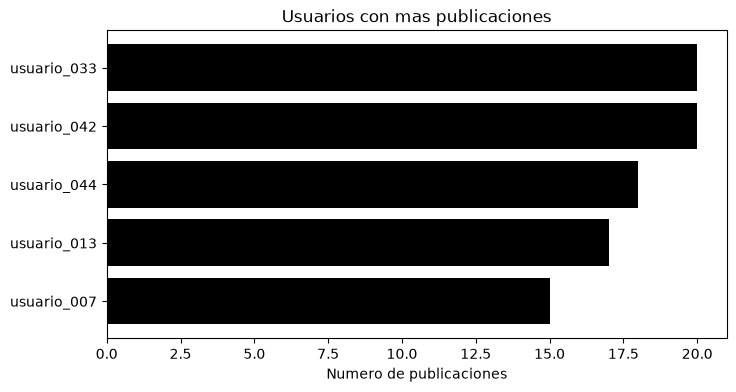

In [87]:
pVentas = publi_usuario.groupby("username")["user_id"].count()
pVentas =pVentas.sort_values(ascending=False).head(5)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["black"])
plt.figure(figsize=(8,4))
plt.barh(pVentas.index, pVentas.values)
plt.gca().invert_yaxis()
plt.xlabel("Numero de publicaciones")
plt.title("Usuarios con mas publicaciones")
plt.show()


In [52]:
pVentas = publi_usuario.groupby("username").size()
print(pVentas.idxmax()," ",pVentas.max())

usuario_033   20


## Que publicacion cuesta mas de [x] 
* publiRango = publicaciones[publicaciones["price"]>500]  
* {variable} = DATAFRAME[CONDICION]  
### Salida   
#### publiRango =publiRango.sort_values(by="price", ascending=False)  
* {variable} = {variable}.sort_values(by="{columna}", ascending={Bool})  
#### publiRango[["title","price"]].head(5)
* {variable}[["{columnas},{columnas}]].head({n}) **n** entero cantidad de registros 

In [ ]:
publicaciones.head()

In [ ]:
publiRango = publicaciones[publicaciones["price"]>500]
publiRango =publiRango.sort_values(by="price", ascending=False)
publiRango[["title","price"]].head(5)

## **Categoria que tiene mas publicaciones**

In [88]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias.head()

,id_x,user_id,category_id,title,description,price,condition,status,created_at,id_y,name
0,2,a13d0e90-f4e6-4a44-99f9-8af5ada34c25,1,PruebaDeProducto,Esta prueba se hizo para la explicacion del in...,67.76,nuevo,active,2026-10-08 05:58:54.974660+00:00,1,Electronica
1,3,68c4b116-0593-4e92-8248-e395e408af52,1,SegundaPrueba,Esto es una prueba para ver si todo funciona bien,39.90,Nuevo,active,2026-10-08 06:12:34.675366+00:00,1,Electronica
2,4,004f01a5-b301-47ef-9cf6-3fc73a7886ad,1,Probando1234,esto es una prueba,450.00,Nuevo,active,2026-10-09 04:32:52.218869+00:00,1,Electronica
3,1,68c4b116-0593-4e92-8248-e395e408af52,1,PruebaProbadora,EstoEsUnAprueba,67.67,agotado,desactive,2026-10-06 21:26:14.594351+00:00,1,Electronica
4,5,cec70406-ca8d-46b4-a7b6-a6777f456272,1,Probando123,HOla,39.00,activo,active,2026-10-09 15:25:52.697624+00:00,1,Electronica


In [153]:
# hacer un merge
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name")["category_id"].count()
publiCategorias.sort_values(ascending=False)

name
Electronica                   38
Automotriz                    36
Ropa                          34
Instrumentos musicales        32
Deportes                      29
Música                        29
Coleccionables                28
Herramientas                  27
Computación                   26
Belleza y cuidado personal    25
Electrodomésticos             24
Consolas                      24
Fotografía                    23
Tecnología                    23
Hogar                         22
Oficina y papelería           21
Mascotas                      21
Calzado                       20
Videojuegos                   20
Juguetes                      19
Celulares y accesorios        19
Muebles                       18
Libros                        16
Otros                         16
Accesorios                    15
Name: category_id, dtype: int64

## Grafico tarta categorias

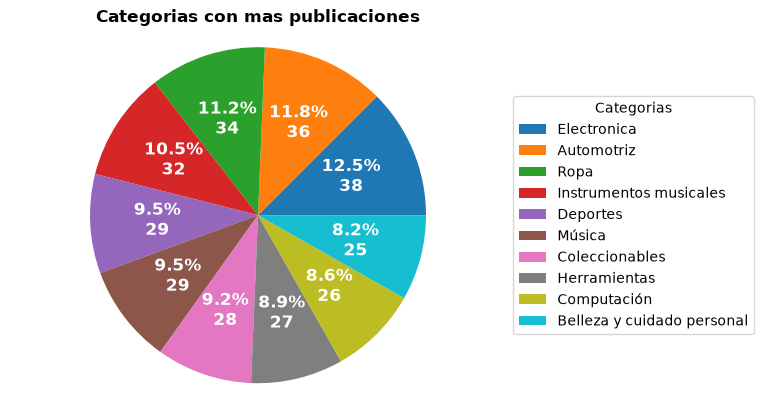

In [183]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name")["category_id"].count()
publiCategorias = publiCategorias.sort_values(ascending=False).head(10)
colores = plt.cm.tab10(np.linspace(0, 1, len(publiCategorias)))
fig, ax = plt.subplots()
pie = ax.pie(publiCategorias.values, 
       colors=colores, radius=0.9,)

ax.pie_label(pie,'{frac:.1%}\n{absval:d}',
       textprops=dict(color="w",size=12, weight="bold"))
ax.legend(pie.wedges, publiCategorias.index ,title="Categorias",loc="center left", bbox_to_anchor=(1, 0, 0.5, 1) )
ax.set_title("Categorias con mas publicaciones", weight="bold")
ax.axis("equal")
plt.show()

In [ ]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name").size()
publiCategorias.sort_values(ascending=False)

## Cual es el precio promedio de cada categoria

In [ ]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio.sort_values(ascending=False)

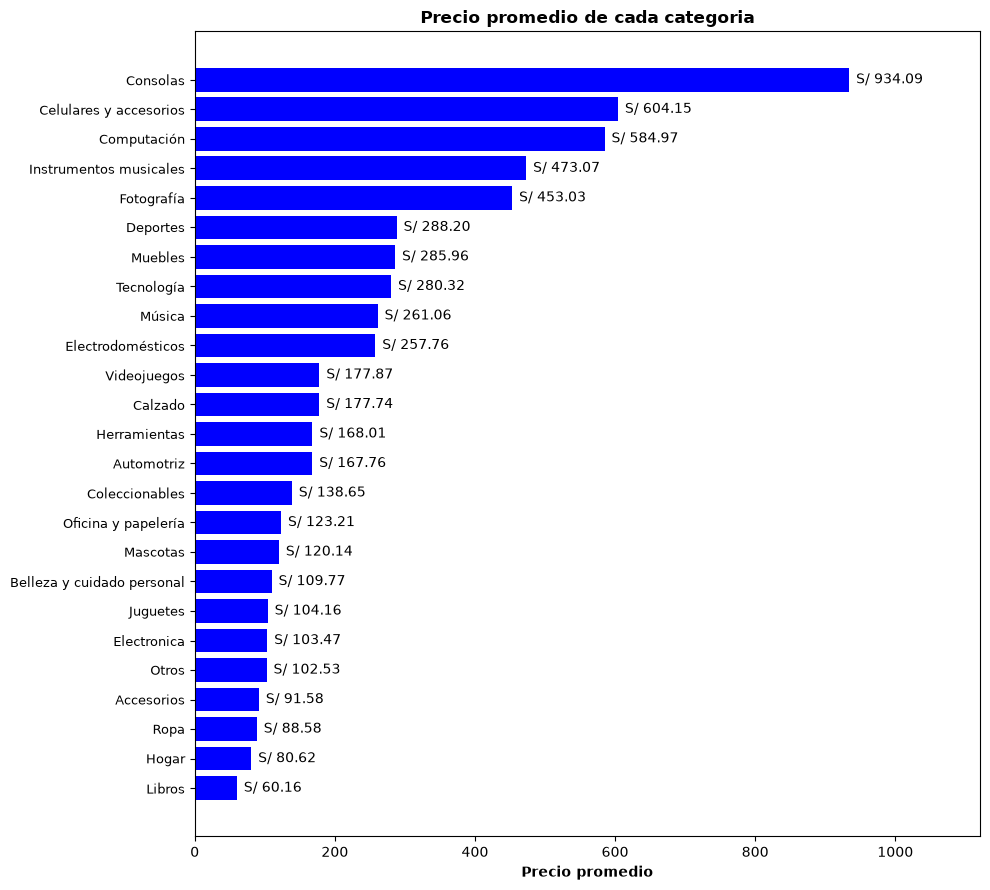

In [250]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio = catePromedio.sort_values(ascending=False)
fig, ax=plt.subplots(figsize=(10,9))
barras = ax.barh(catePromedio.index, catePromedio.values, color ="Blue")
ax.invert_yaxis()
ax.set_xlabel("Precio promedio", weight="bold")
ax.set_title("Precio promedio de cada categoria", weight="bold")
ax.tick_params(axis='y', labelsize=9)
ax.bar_label(barras, fmt="S/ %.2f", padding=5)
ax.set_xlim(0, catePromedio.max()*1.20)
plt.tight_layout()
plt.show()

___
### Usuario que recibio mas reseñas

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas.sort_values(ascending=False)


___
### Usuario que recibio mas reseñas positivas


In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas[usuResenas["rating"]>=4]
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas.sort_values(ascending=False)

___
### Usuario que recibio mas reseñas negativas

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas[usuResenas["rating"]<4]
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas.sort_values(ascending=False)

___
### Quien escribio mas reseñas


In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewer_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewer_id"].count()
usuResenas.sort_values(ascending=False)